# Volatility-Volume-based Order Management
**Columbia University — IEOR4703 Monte Carlo Simulation Methods (Hirsa)**  
**Term Project 2**

---

## Research Question

> *Given a trade decision to buy or sell, at what price level should we place a limit order — conditioned on the current market regime — to maximize expected execution quality?*

We build empirical conditional probability distributions of intra-period price range (rangeUp, rangeDn) conditioned on a three-dimensional regime state (volume × volatility × direction), then use **Monte Carlo simulation** to propagate uncertainty through execution outcomes. The result is a statistically rigorous framework for limit order placement that adapts to market conditions.

**Note on the synthetic signal:** A simple momentum signal generates Buy/Sell events purely as a testing vehicle. This project is about *how* to execute a decision, not about predicting price direction.

**Assets:** Nasdaq futures (NQ, primary) · Gold futures (GC, secondary)  
**Data:** 1-minute OHLC futures data with volume

---
## Section 0 — Configuration

All parameters live here. To change asset, holding period, or model hyperparameters, edit only this cell.

In [33]:
# ─────────────────────────────────────────────
# SECTION 0 — CONFIGURATION
# Edit only this cell to change asset / tau / model params
# ─────────────────────────────────────────────

import os

# --- Asset & Data ---
ASSET            = 'NQ'        # 'NQ' (Nasdaq) or 'GC' (Gold)
TICK_SIZE        = 0.25        # NQ=0.25, GC=0.10
DATA_DIR         = 'data/'
MIN_BARS_PER_DAY = 350         # active-day filter (~90% of 390-min US session)

# --- Holding Period ---
TAU              = 5           # minutes; valid: 5, 10, 15, 30, 60

# --- AI Agent Signal ---
USE_AI_AGENT_SIGNAL = True     # True = use AIAgent CSV; False = use synthetic signal

# --- EWMA State Engine ---
HALF_LIFE        = 20          # EWMA half-life in tau-bars
M_STATES         = 3           # volume regime bins  (low / medium / high)
N_STATES         = 3           # volatility regime bins
K_STATES         = 3           # direction bins      (down / flat / up)
DIR_THRESHOLD    = 1.0         # ticks; dead-band around zero for direction state

# --- ePDF Builder ---
BURN_IN          = 500         # tau-bars before ePDF estimation begins
MIN_EPDF_SAMPLES = 30          # min obs per state cell before ePDF is trusted
SMOOTHING_ALPHA  = 0.5         # Laplace/Jeffreys smoothing pseudo-count per tick level

# --- Train / Test Split ---
TEST_START_FRAC  = 0.60        # first 60% = in-sample; remaining 40% = out-of-sample test

# --- Monte Carlo Simulation ---
N_MC_PATHS       = 10_000      # simulation paths per (state, limit-level) query
MC_CONFIDENCE    = 0.95        # CI level for fill-rate and improvement bands
BOOTSTRAP_REPS   = 1_000       # bootstrap resamples for ePDF estimation uncertainty

# --- Backtest & Order Placement ---
FILL_PROB_THRESHOLD = 0.60     # min fill probability required to place a limit order

# --- Synthetic Signal fallback (used only when USE_AI_AGENT_SIGNAL = False) ---
SIGNAL_TYPE      = 'momentum'  # 'momentum' or 'mean_reversion'
SIGNAL_LOOKBACK  = 10          # bars for signal EWMA
SIGNAL_THRESHOLD = 1.0         # ticks; dead-band for Flat classification

# --- Reproducibility ---
RANDOM_SEED      = 42

print(f"Config loaded: ASSET={ASSET}, TAU={TAU}min, TICK={TICK_SIZE}, "
      f"states={M_STATES}x{N_STATES}x{K_STATES}, half_life={HALF_LIFE}, "
      f"burn_in={BURN_IN}, MC_paths={N_MC_PATHS:,}, "
      f"AI_signal={USE_AI_AGENT_SIGNAL}")


Config loaded: ASSET=NQ, TAU=5min, TICK=0.25, states=3x3x3, half_life=20, burn_in=500, MC_paths=10,000, AI_signal=True


---
## Section 1 — Imports & Setup

In [34]:
# ─────────────────────────────────────────────
# SECTION 1 — IMPORTS & SETUP
# ─────────────────────────────────────────────

import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.lines import Line2D
import seaborn as sns
from collections import defaultdict
from datetime import datetime, timedelta
from pathlib import Path
from itertools import product
from typing import Dict, List, Optional, Tuple

np.random.seed(RANDOM_SEED)

# Plot style
plt.rcParams.update({
    'figure.dpi': 120,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.3,
    'font.size': 11,
})
PALETTE = sns.color_palette('tab10')

print("Imports complete.")

Imports complete.


---
## Section 2 — Data Loading & Preprocessing

**Data format:** Each CSV row is a 1-minute snapshot `[excel_date, hour, min, price, price, price, price, volume, ...]` where open=high=low=close (single representative trade price per minute). True OHLC bars are reconstructed in Section 3 by aggregating τ consecutive rows.

**Rollover logic:** Multiple expiry contracts overlap. We detect the rollover date as the first day where the next contract's daily volume exceeds the front contract's, then stitch contracts accordingly — consistent with Figure 1 of the project spec.

**Active day filter:** Days with fewer than `MIN_BARS_PER_DAY` 1-minute rows are discarded (data quality failures, early closes, holidays).

Loading NQ data (AIAgent date window)...
  Loaded NQH20.csv: 74,512 rows (2020-01-02 → 2020-03-20)
  Loaded NQM20.csv: 91,550 rows (2020-01-02 → 2020-05-31)
  Loaded NQU20.csv: 7,267 rows (2020-01-02 → 2020-05-31)

  → NQ: 141,733 bars across 126 active days (2020-01-02 → 2020-05-31)


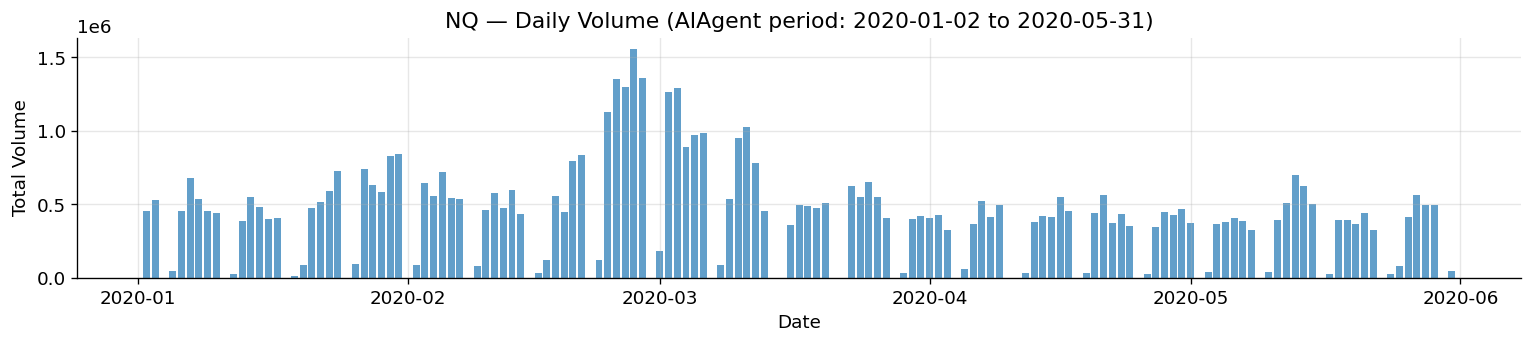

Date range: 2020-01-02 → 2020-05-31
NOTE: This window includes the COVID crash (Feb–Mar 2020) for NQ.


In [35]:
# ─────────────────────────────────────────────
# SECTION 2 — DATA LOADING & PREPROCESSING
# ─────────────────────────────────────────────

from datetime import date

# Asset registry: futures contracts + paired AIAgent signal file + date range
# Date ranges match the AIAgent coverage windows exactly.
ASSET_REGISTRY = {
    'NQ': {
        'folder':      'Nasdaq',
        'contracts':   ['NQH20.csv', 'NQM20.csv', 'NQU20.csv'],
        'tick_size':   0.25,
        'ai_agent':    'AIAgent_Nasdaq.csv',
        'date_start':  date(2020, 1, 2),    # AIAgent coverage window
        'date_end':    date(2020, 5, 31),
    },
    'GC': {
        'folder':      'Gold',
        'contracts':   ['GCG24.csv', 'GCJ24.csv', 'GCM24.csv', 'GCQ24.csv'],
        'tick_size':   0.10,
        'ai_agent':    'AIAgent_Gold.csv',
        'date_start':  date(2024, 1, 2),
        'date_end':    date(2024, 5, 31),
    },
}


def _excel_to_date(serial: int) -> datetime:
    """Convert Excel serial date integer to Python datetime."""
    return datetime(1899, 12, 30) + timedelta(days=int(serial))


def _parse_contract(filepath: str) -> pd.DataFrame:
    """
    Parse a single futures contract CSV into a clean DataFrame.
    Columns: datetime (index), price, volume.
    """
    rows = []
    with open(filepath) as f:
        for line in f:
            parts = line.strip().split(',')
            if len(parts) < 8:
                continue
            try:
                date_serial = int(parts[0].strip())
                hour        = int(parts[1].strip())
                minute      = int(parts[2].strip())
                price       = float(parts[3].strip())
                volume      = int(parts[7].strip())
            except (ValueError, IndexError):
                continue
            dt = _excel_to_date(date_serial).replace(hour=hour, minute=minute)
            rows.append({'datetime': dt, 'price': price, 'volume': volume})

    df = pd.DataFrame(rows).set_index('datetime').sort_index()
    df = df[df['volume'] > 0]
    return df


def _detect_rollover(front: pd.DataFrame, back: pd.DataFrame) -> Optional[datetime]:
    """First date where back contract daily volume exceeds front contract."""
    front_daily = front['volume'].resample('D').sum().rename('front')
    back_daily  = back['volume'].resample('D').sum().rename('back')
    combined    = pd.concat([front_daily, back_daily], axis=1).dropna()
    crossover   = combined[combined['back'] > combined['front']]
    if crossover.empty:
        return None
    return crossover.index[0].to_pydatetime()


def _stitch_contracts(contract_dfs: List[pd.DataFrame]) -> pd.DataFrame:
    """Stitch contracts via volume-crossover rollover detection."""
    if len(contract_dfs) == 1:
        return contract_dfs[0]
    result = contract_dfs[0].copy()
    for back_df in contract_dfs[1:]:
        rollover_dt = _detect_rollover(result, back_df)
        if rollover_dt is None:
            rollover_dt = result.index[-1]
        result = pd.concat([
            result[result.index < rollover_dt],
            back_df[back_df.index >= rollover_dt],
        ]).sort_index()
    return result


def _filter_active_days(df: pd.DataFrame, min_bars: int) -> pd.DataFrame:
    """Keep only calendar dates with at least min_bars 1-minute rows."""
    date_counts = df.groupby(df.index.date).size()
    valid_dates  = date_counts[date_counts >= min_bars].index
    mask         = pd.Series(df.index.date, index=df.index).isin(valid_dates)
    return df[mask]


def load_data(asset: str,
              data_dir: str       = DATA_DIR,
              min_bars_per_day: int = MIN_BARS_PER_DAY,
              date_start=None,
              date_end=None) -> pd.DataFrame:
    """
    Load, stitch, and clean all contracts for the given asset.
    If date_start / date_end are provided, restrict to that date window
    (used to align with the AIAgent signal coverage period).

    Returns
    -------
    pd.DataFrame with columns [price, volume], datetime index.
    """
    if asset not in ASSET_REGISTRY:
        raise ValueError(f"Unknown asset '{asset}'. Available: {list(ASSET_REGISTRY)}")

    meta      = ASSET_REGISTRY[asset]
    folder    = Path(data_dir) / meta['folder']
    contracts = meta['contracts']

    # Use registry date range if not overridden
    date_start = date_start or meta.get('date_start')
    date_end   = date_end   or meta.get('date_end')

    dfs = []
    for fname in contracts:
        fpath = folder / fname
        if not fpath.exists():
            print(f"  [warn] {fpath} not found — skipping")
            continue
        df = _parse_contract(str(fpath))
        # Pre-filter each contract to date window before stitching
        if date_start:
            df = df[df.index.date >= date_start]
        if date_end:
            df = df[df.index.date <= date_end]
        if df.empty:
            continue
        dfs.append(df)
        print(f"  Loaded {fname}: {len(df):,} rows "
              f"({df.index[0].date()} → {df.index[-1].date()})")

    if not dfs:
        raise FileNotFoundError(f"No data found for {asset} in {folder} for given date range")

    raw   = _stitch_contracts(dfs)
    clean = _filter_active_days(raw, min_bars_per_day)

    n_days = clean.index.normalize().nunique()
    print(f"\n  → {asset}: {len(clean):,} bars across {n_days} active days "
          f"({clean.index[0].date()} → {clean.index[-1].date()})")
    return clean


# ── Run ──
print(f"Loading {ASSET} data (AIAgent date window)...")
raw_df = load_data(ASSET, DATA_DIR, MIN_BARS_PER_DAY)

daily_vol = raw_df['volume'].resample('D').sum()
fig, ax = plt.subplots(figsize=(13, 3))
ax.bar(daily_vol.index, daily_vol.values, width=0.8, color=PALETTE[0], alpha=0.7)
ax.set(title=f'{ASSET} — Daily Volume (AIAgent period: {ASSET_REGISTRY[ASSET]["date_start"]} to {ASSET_REGISTRY[ASSET]["date_end"]})',
       xlabel='Date', ylabel='Total Volume')
plt.tight_layout()
plt.show()
print(f"Date range: {raw_df.index[0].date()} → {raw_df.index[-1].date()}")
print(f"NOTE: This window includes the COVID crash (Feb–Mar 2020) for NQ.")


---
## Section 3 — OHLC Reconstruction

Each 1-minute row carries a single representative price. We aggregate τ consecutive rows into a proper OHLC bar.

**Non-overlapping windows** are used deliberately: overlapping windows produce ~τ× more samples but each adjacent pair shares τ−1 minutes of data. The resulting serial correlation violates the i.i.d. assumption required by the Monte Carlo sampling step and inflates apparent sample sizes in the ePDF histograms. The cost is fewer training observations, which is offset by the conservative `BURN_IN` setting.

Windows are day-aligned; partial windows at session end are discarded to avoid spurious cross-session ranges.

In [36]:
# ─────────────────────────────────────────────
# SECTION 3 — OHLC RECONSTRUCTION
# ─────────────────────────────────────────────

def build_ohlc(df: pd.DataFrame, tau: int) -> pd.DataFrame:
    """
    Aggregate 1-min price/volume rows into non-overlapping tau-min OHLC bars.

    Parameters
    ----------
    df  : DataFrame with columns [price, volume], datetime index
    tau : holding period in minutes

    Returns
    -------
    DataFrame with columns [open, high, low, close, volume], one row per tau-min bar.
    """
    records = []

    for date, day_df in df.groupby(df.index.date):
        day_df = day_df.sort_index()
        prices = day_df['price'].values
        volumes = day_df['volume'].values
        times = day_df.index
        n = len(prices)

        # Walk through the day in non-overlapping tau-minute windows
        # Only include complete windows (discard last partial window)
        for start in range(0, n - tau + 1, tau):
            end = start + tau
            window_prices  = prices[start:end]
            window_volumes = volumes[start:end]
            records.append({
                'datetime': times[start],
                'open':     window_prices[0],
                'high':     window_prices.max(),
                'low':      window_prices.min(),
                'close':    window_prices[-1],
                'volume':   window_volumes.sum(),
            })

    ohlc = pd.DataFrame(records).set_index('datetime').sort_index()
    return ohlc


# ── Run ──
print(f"Building {TAU}-min OHLC bars...")
ohlc_df = build_ohlc(raw_df, TAU)
print(f"  {len(ohlc_df):,} bars | "
      f"avg range (raw): {(ohlc_df['high'] - ohlc_df['low']).mean():.4f} price units")
print(ohlc_df.head(3).to_string())

Building 5-min OHLC bars...
  28,321 bars | avg range (raw): 9.5154 price units
                        open     high      low    close  volume
datetime                                                       
2020-01-02 00:00:00  8788.25  8788.25  8787.25  8787.75      98
2020-01-02 00:05:00  8787.50  8787.50  8786.00  8786.00     120
2020-01-02 00:10:00  8786.00  8786.50  8785.50  8785.50     170


---
## Section 4 — Range Computation

Ranges are expressed as **integer tick counts** to make the ePDF a discrete probability mass function with natural support {0, 1, 2, ...}. This eliminates floating-point artifacts when comparing across assets with different price scales and simplifies Monte Carlo sampling (draw an integer from a PMF).

Identity: `R = R_up + R_dn` holds exactly after rounding because `(H−L) = (H−O) + (O−L)`.

Range stats (5-min bars, tick=0.25):
              R     R_up      R_dn
count  28321.00  28321.0  28321.00
mean      38.06     18.9     19.16
std       43.33     33.2     34.03
min        0.00      0.0      0.00
25%       12.00      0.0      0.00
50%       24.00      7.0      7.00
75%       47.00     23.0     24.00
max     1263.00    643.0   1263.00

Identity R = R_up + R_dn holds: 100.0000%


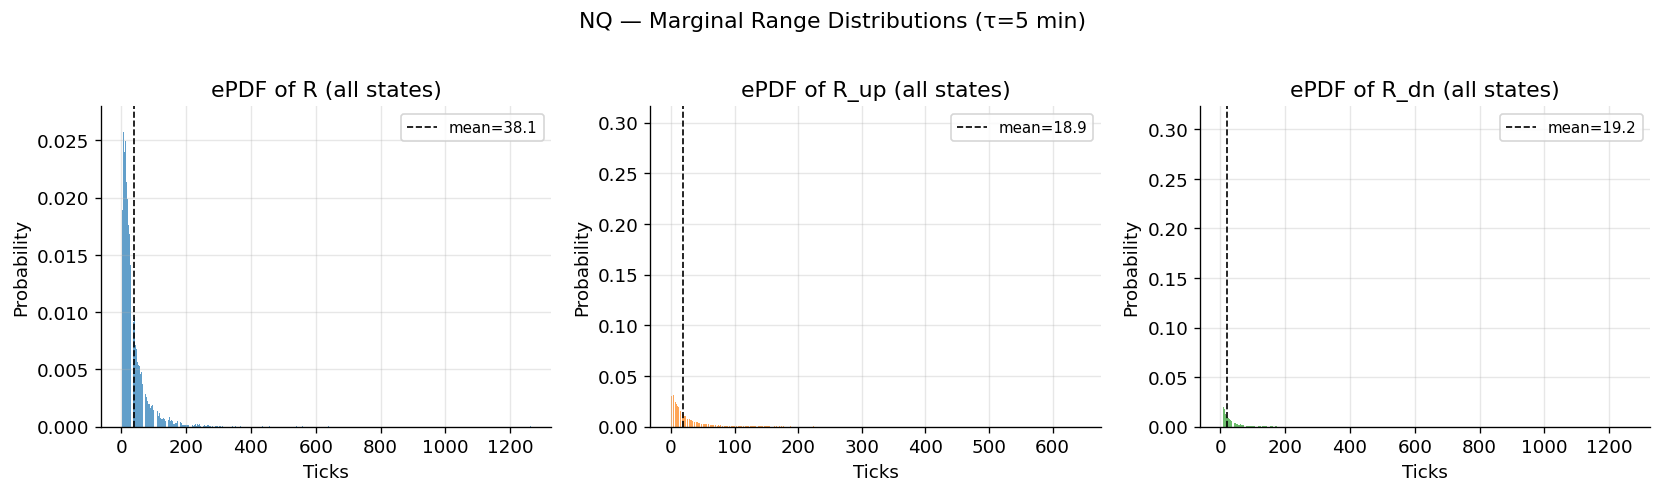

In [37]:
# ─────────────────────────────────────────────
# SECTION 4 — RANGE COMPUTATION
# ─────────────────────────────────────────────

def compute_ranges(ohlc: pd.DataFrame, tick_size: float) -> pd.DataFrame:
    """
    Compute range quantities in integer tick units.

    Adds columns:
      R       — total range   = (high − low)  / tick   [integer ticks]
      R_up    — up excursion  = (high − open) / tick   [integer ticks]
      R_dn    — down exc.     = (open − low)  / tick   [integer ticks]
      delta_x — close − open in raw price units (signed, for direction state)
    """
    df = ohlc.copy()
    df['R']       = ((df['high'] - df['low'])   / tick_size).round().astype(int)
    df['R_up']    = ((df['high'] - df['open'])  / tick_size).round().astype(int)
    df['R_dn']    = ((df['open'] - df['low'])   / tick_size).round().astype(int)
    df['delta_x'] = df['close'] - df['open']

    # Clip to non-negative (floating point can produce tiny negatives)
    df['R']    = df['R'].clip(lower=0)
    df['R_up'] = df['R_up'].clip(lower=0)
    df['R_dn'] = df['R_dn'].clip(lower=0)
    return df


# ── Run ──
ohlc_df = compute_ranges(ohlc_df, TICK_SIZE)

print(f"Range stats ({TAU}-min bars, tick={TICK_SIZE}):")
print(ohlc_df[['R', 'R_up', 'R_dn']].describe().round(2).to_string())

# Verify identity R = R_up + R_dn
identity_holds = (ohlc_df['R'] == ohlc_df['R_up'] + ohlc_df['R_dn']).mean()
print(f"\nIdentity R = R_up + R_dn holds: {identity_holds:.4%}")

# Distribution plot
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col, color in zip(axes, ['R', 'R_up', 'R_dn'], PALETTE[:3]):
    vals = ohlc_df[col]
    counts = vals.value_counts().sort_index()
    ax.bar(counts.index, counts.values / counts.sum(),
           color=color, alpha=0.7, width=0.8)
    ax.set(title=f'ePDF of {col} (all states)',
           xlabel='Ticks', ylabel='Probability')
    ax.axvline(vals.mean(), color='k', linestyle='--', linewidth=1,
               label=f'mean={vals.mean():.1f}')
    ax.legend(fontsize=9)
plt.suptitle(f'{ASSET} — Marginal Range Distributions (τ={TAU} min)', y=1.02)
plt.tight_layout()
plt.show()

---
## Section 5 — EWMA State Engine

We classify each bar into a three-dimensional regime state `(vol_state, sig_state, dir_state)` using exponentially weighted moving averages of volume and range (volatility proxy). Algorithm 1 from the project spec is implemented **strictly out-of-sample**: at bar `j`, only information from bars `0..j−1` is used.

State bins are determined by **out-of-sample quantile thresholds**: at each bar `j`, tercile boundaries are computed from the EWMA values seen so far. This avoids look-ahead bias in the regime classification itself.

Computing EWMA states...
  Active bars (post burn-in): 27,821

State distributions:
  Volume: state 0=36.5%, state 1=33.2%, state 2=30.2%
  Volatility: state 0=14.1%, state 1=41.5%, state 2=44.4%
  Direction: state 0=45.5%, state 1=7.4%, state 2=47.1%


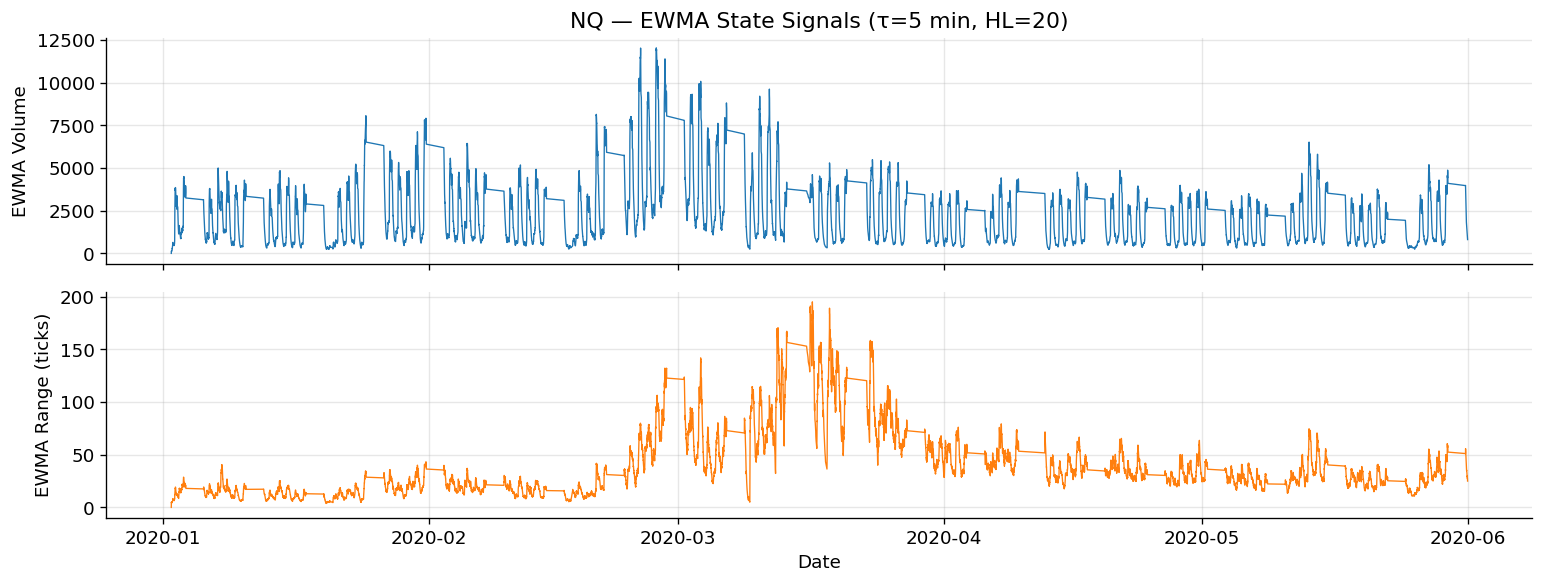

In [38]:
# ─────────────────────────────────────────────
# SECTION 5 — EWMA STATE ENGINE
# ─────────────────────────────────────────────

def _ewma_recursive(series: np.ndarray, half_life: int) -> Tuple[np.ndarray, np.ndarray]:
    """
    Compute recursive exponentially weighted mean and std (Algorithm 1, project spec).
    Uses eta_{j-1} at step j to avoid any look-ahead.

    Returns
    -------
    ewma  : array of EWMA values
    ewmstd: array of EWMA std values (sqrt of EWMV)
    """
    lam = 2 ** (-1.0 / half_life)   # decay factor
    n = len(series)

    ewma   = np.zeros(n)
    ewmstd = np.zeros(n)
    sumW   = 0.0
    sumWX  = 0.0
    sumWSS = 0.0

    for j in range(1, n):
        eta_prev = series[j - 1]    # strict lag-1: use previous bar
        if j == 1:
            sumW   = 1.0
            sumWX  = eta_prev
            ewma[j] = eta_prev
            sumWSS  = 0.0
            ewmstd[j] = 0.0
        else:
            sumW   = lam * sumW   + 1.0
            sumWX  = lam * sumWX  + eta_prev
            ewma[j] = sumWX / sumW
            sumWSS = lam * sumWSS + (eta_prev - ewma[j]) ** 2
            ewmstd[j] = np.sqrt(sumWSS / sumW)

    return ewma, ewmstd


def _bin_to_states(values: np.ndarray,
                   history: np.ndarray,
                   n_states: int) -> int:
    """
    Assign a single value to a state bin [0, n_states-1] using quantile
    thresholds computed from the provided history (out-of-sample).
    """
    if len(history) < n_states + 1:
        return 0   # not enough history — assign to lowest state
    quantiles = np.linspace(0, 100, n_states + 1)[1:-1]  # interior breakpoints
    thresholds = np.percentile(history, quantiles)
    return int(np.searchsorted(thresholds, values, side='right'))


def compute_ewma_states(df: pd.DataFrame,
                        half_life: int  = HALF_LIFE,
                        m_states: int   = M_STATES,
                        n_states: int   = N_STATES,
                        k_states: int   = K_STATES,
                        dir_threshold: float = DIR_THRESHOLD,
                        burn_in: int    = BURN_IN) -> pd.DataFrame:
    """
    Add vol_state, sig_state, dir_state columns to the OHLC DataFrame.
    All states are strictly out-of-sample: state at bar j uses only bars 0..j-1.

    States are integers in [0, n_states-1].
    Bars before burn_in receive state=-1 (excluded from ePDF training).
    """
    df = df.copy()
    n = len(df)

    volumes  = df['volume'].values.astype(float)
    ranges   = df['R'].values.astype(float)
    delta_xs = df['delta_x'].values

    # Compute EWMA of volume and range (volatility proxy)
    ewma_vol, _  = _ewma_recursive(volumes,  half_life)
    ewma_rng, _  = _ewma_recursive(ranges,   half_life)

    vol_states = np.full(n, -1, dtype=int)
    sig_states = np.full(n, -1, dtype=int)
    dir_states = np.full(n, -1, dtype=int)

    dir_tick = dir_threshold * TICK_SIZE  # convert ticks to price units

    for j in range(burn_in, n):
        # Out-of-sample history: EWMA values computed at bars 0..j-1
        # (ewma_vol[j] already uses only series[0..j-1] due to lag-1 update)
        history_vol = ewma_vol[1:j]   # exclude index 0 (always 0)
        history_rng = ewma_rng[1:j]

        vol_states[j] = _bin_to_states(ewma_vol[j], history_vol, m_states)
        sig_states[j] = _bin_to_states(ewma_rng[j], history_rng, n_states)

        # Direction state: use previous bar's delta_x (lag-1)
        prev_dx = delta_xs[j - 1]
        if   prev_dx < -dir_tick:
            dir_states[j] = 0   # down
        elif prev_dx >  dir_tick:
            dir_states[j] = 2   # up
        else:
            dir_states[j] = 1   # flat

    df['vol_state'] = vol_states
    df['sig_state'] = sig_states
    df['dir_state'] = dir_states
    df['ewma_vol']  = ewma_vol
    df['ewma_rng']  = ewma_rng
    return df


# ── Run ──
print("Computing EWMA states...")
ohlc_df = compute_ewma_states(ohlc_df)

active = ohlc_df[ohlc_df['vol_state'] >= 0]
print(f"  Active bars (post burn-in): {len(active):,}")
print("\nState distributions:")
for col, label in [('vol_state', 'Volume'), ('sig_state', 'Volatility'), ('dir_state', 'Direction')]:
    counts = active[col].value_counts().sort_index()
    pcts = (counts / counts.sum() * 100).round(1)
    print(f"  {label}: " + ", ".join(f"state {k}={v}%" for k, v in pcts.items()))

# EWMA time series plot
fig, axes = plt.subplots(2, 1, figsize=(13, 5), sharex=True)
axes[0].plot(ohlc_df.index, ohlc_df['ewma_vol'], color=PALETTE[0], linewidth=0.8)
axes[0].set(ylabel='EWMA Volume', title=f'{ASSET} — EWMA State Signals (τ={TAU} min, HL={HALF_LIFE})')
axes[1].plot(ohlc_df.index, ohlc_df['ewma_rng'], color=PALETTE[1], linewidth=0.8)
axes[1].set(ylabel='EWMA Range (ticks)', xlabel='Date')
plt.tight_layout()
plt.show()


---
## Section 6 — ePDF Builder

We build conditional empirical probability mass functions $P(R_{\text{up}} = \ell_1 \mid \text{state})$ and $P(R_{\text{dn}} = \ell_2 \mid \text{state})$ online, one bar at a time, strictly out-of-sample.

**Sparse-state problem:** With 27 state combinations (3×3×3), some cells accumulate few observations — especially extreme regime combinations. Two mitigations are applied:
1. **Laplace/Jeffreys smoothing** (`α=0.5`): adds pseudo-counts to every tick level before normalizing, preventing zero-probability tails.
2. **Three-tier fallback**: state ePDF → marginal ePDF (pooled) → market order at open.

The survival function $P(R_{\text{up}} \geq \ell_1 \mid \text{state})$ is the core quantity used by the Monte Carlo layer and backtest to determine fill probability.

In [39]:
# ─────────────────────────────────────────────
# SECTION 6 — ePDF BUILDER
# ─────────────────────────────────────────────

class EpdfStore:
    """
    Online store of conditional empirical PMFs for R, R_up, R_dn.

    Keyed by (vol_state, sig_state, dir_state). Each cell holds count
    arrays indexed by integer tick count. Supports Laplace smoothing
    and a three-tier fallback hierarchy.
    """

    def __init__(self, smoothing_alpha: float = SMOOTHING_ALPHA,
                 min_samples: int = MIN_EPDF_SAMPLES):
        self.alpha       = smoothing_alpha
        self.min_samples = min_samples

        # Nested dicts: state_key -> {'R': array, 'R_up': array, 'R_dn': array}
        self._counts: Dict[Tuple, Dict[str, np.ndarray]] = defaultdict(
            lambda: {'R': np.zeros(1), 'R_up': np.zeros(1), 'R_dn': np.zeros(1)}
        )
        # Marginal counts (pooled across all states)
        self._marginal: Dict[str, np.ndarray] = {
            'R': np.zeros(1), 'R_up': np.zeros(1), 'R_dn': np.zeros(1)
        }

    def _extend_array(self, arr: np.ndarray, size: int) -> np.ndarray:
        """Grow count array to at least `size` elements."""
        if len(arr) < size:
            arr = np.append(arr, np.zeros(size - len(arr)))
        return arr

    def update(self, state: Tuple[int, int, int],
               R: int, R_up: int, R_dn: int) -> None:
        """Add one observation to the state cell and the marginal."""
        for store in [self._counts[state], self._marginal]:
            store['R']    = self._extend_array(store['R'],    R    + 1)
            store['R_up'] = self._extend_array(store['R_up'], R_up + 1)
            store['R_dn'] = self._extend_array(store['R_dn'], R_dn + 1)
            store['R'][R]       += 1
            store['R_up'][R_up] += 1
            store['R_dn'][R_dn] += 1

    def _pmf(self, counts: np.ndarray) -> np.ndarray:
        """Normalize count array to PMF with Laplace smoothing."""
        L = len(counts)
        smoothed = counts + self.alpha
        return smoothed / smoothed.sum()

    def _survival(self, counts: np.ndarray) -> np.ndarray:
        """Compute survival function P(X >= l) for l = 0, 1, ..., L-1."""
        pmf = self._pmf(counts)
        return 1.0 - np.cumsum(pmf) + pmf  # P(X >= l) = 1 - CDF(l-1)

    def _total_count(self, state: Tuple) -> int:
        return int(self._counts[state]['R_up'].sum())

    def _marginal_count(self) -> int:
        return int(self._marginal['R_up'].sum())

    def get_pmf(self, state: Tuple, direction: str) -> np.ndarray:
        """
        Return PMF for given state and direction ('R_up' or 'R_dn').
        Applies three-tier fallback: state -> marginal -> uniform.
        """
        assert direction in ('R_up', 'R_dn')

        if self._total_count(state) >= self.min_samples:
            return self._pmf(self._counts[state][direction])
        elif self._marginal_count() >= self.min_samples:
            return self._pmf(self._marginal[direction])  # tier 2: marginal
        else:
            return np.array([1.0])   # tier 3: effectively a market order

    def get_survival(self, state: Tuple, direction: str) -> np.ndarray:
        """
        Return survival function P(X >= l) for given state and direction.
        """
        if self._total_count(state) >= self.min_samples:
            return self._survival(self._counts[state][direction])
        elif self._marginal_count() >= self.min_samples:
            return self._survival(self._marginal[direction])
        else:
            return np.array([1.0])

    def fill_prob(self, state: Tuple, direction: str, ell: int) -> float:
        """
        P(R_up >= ell | state) for sell limit, or P(R_dn >= ell | state) for buy.
        """
        sf = self.get_survival(state, direction)
        if ell >= len(sf):
            return 0.0
        return float(sf[ell])

    def sample_range(self, state: Tuple, direction: str,
                     n: int, rng: np.random.Generator) -> np.ndarray:
        """Draw n samples from the conditional PMF (for Monte Carlo simulation)."""
        pmf = self.get_pmf(state, direction)
        return rng.choice(len(pmf), size=n, p=pmf)

    def state_count(self, state: Tuple) -> int:
        return self._total_count(state)


def build_epdf(df: pd.DataFrame,
               burn_in: int = BURN_IN,
               test_start_frac: float = TEST_START_FRAC,
               smoothing_alpha: float = SMOOTHING_ALPHA,
               min_samples: int = MIN_EPDF_SAMPLES) -> Tuple['EpdfStore', int]:
    """
    Build the EpdfStore by processing bars online in chronological order.

    Query-before-update: at each bar j, we first record the ePDF query opportunity
    (for use in backtest), THEN update the counts with bar j's observed ranges.
    This ensures the ePDF at bar j contains only bars 0..j-1.

    Returns
    -------
    store          : EpdfStore with count arrays populated from all bars
    test_start_idx : integer index of the first out-of-sample bar
    """
    store = EpdfStore(smoothing_alpha=smoothing_alpha, min_samples=min_samples)
    n = len(df)
    test_start_idx = int(n * test_start_frac)

    # Precompute arrays for speed
    vol_states = df['vol_state'].values
    sig_states = df['sig_state'].values
    dir_states = df['dir_state'].values
    R_vals     = df['R'].values
    R_up_vals  = df['R_up'].values
    R_dn_vals  = df['R_dn'].values

    for j in range(burn_in, n):
        vs, ss, ds = vol_states[j], sig_states[j], dir_states[j]
        if vs < 0 or ss < 0 or ds < 0:
            continue   # pre-burn-in bar (state=-1)

        # Update ePDF with this bar's observed ranges
        # (query happens at backtest time BEFORE update via test_start_idx)
        store.update(
            state=(vs, ss, ds),
            R=int(R_vals[j]),
            R_up=int(R_up_vals[j]),
            R_dn=int(R_dn_vals[j]),
        )

    return store, test_start_idx


# ── Run ──
print("Building conditional ePDFs...")
epdf_store, test_start_idx = build_epdf(ohlc_df)

active_df = ohlc_df[ohlc_df['vol_state'] >= 0]
print(f"  Test period starts at bar index: {test_start_idx} "
      f"({ohlc_df.index[test_start_idx].date()})")

# Report sample counts per state
print("\nSample counts per state (vol, sig, dir):")
state_counts = {}
for vs, ss, ds in product(range(M_STATES), range(N_STATES), range(K_STATES)):
    cnt = epdf_store.state_count((vs, ss, ds))
    state_counts[(vs, ss, ds)] = cnt

count_df = pd.Series(state_counts).rename('count').reset_index()
count_df.columns = ['vol', 'sig', 'dir', 'count']
print(count_df.pivot_table(index=['vol', 'sig'], columns='dir',
                            values='count', aggfunc='sum').to_string())
sparse = sum(1 for v in state_counts.values() if v < MIN_EPDF_SAMPLES)
print(f"\nSparse cells (<{MIN_EPDF_SAMPLES} samples): {sparse} / 27 — "
      f"will use marginal fallback")

Building conditional ePDFs...
  Test period starts at bar index: 16992 (2020-04-01)

Sample counts per state (vol, sig, dir):
dir         0    1     2
vol sig                 
0   0    1379  636  1478
    1    2438  308  2447
    2     669  122   681
1   0     157   63   178
    1    2052  329  2269
    2    2044  210  1946
2   0       7    7    10
    1     751  122   824
    2    3165  257  3272

Sparse cells (<30 samples): 3 / 27 — will use marginal fallback


---
## Section 7 — Monte Carlo Execution Simulation

Rather than using a single point-estimate from the survival function, we simulate an **ensemble of future execution scenarios** by sampling from the conditional ePDF. This quantifies:

1. **Execution uncertainty**: the distribution of fill outcomes across N_MC_PATHS sampled range realizations
2. **ePDF estimation uncertainty**: bootstrap confidence intervals reflecting finite sample error in the count arrays

The output is an **execution frontier** per regime state — the full tradeoff curve between fill probability and expected price improvement — used to select the optimal limit level `ℓ*`:
$$\ell^* = \arg\max_\ell \mathbb{E}[\text{improvement} \mid \text{state}, \ell] \quad \text{s.t.} \quad P(\text{fill} \mid \text{state}, \ell) \geq \theta$$

Running Monte Carlo simulations across all states...
  Cached 54 (state, direction) combinations


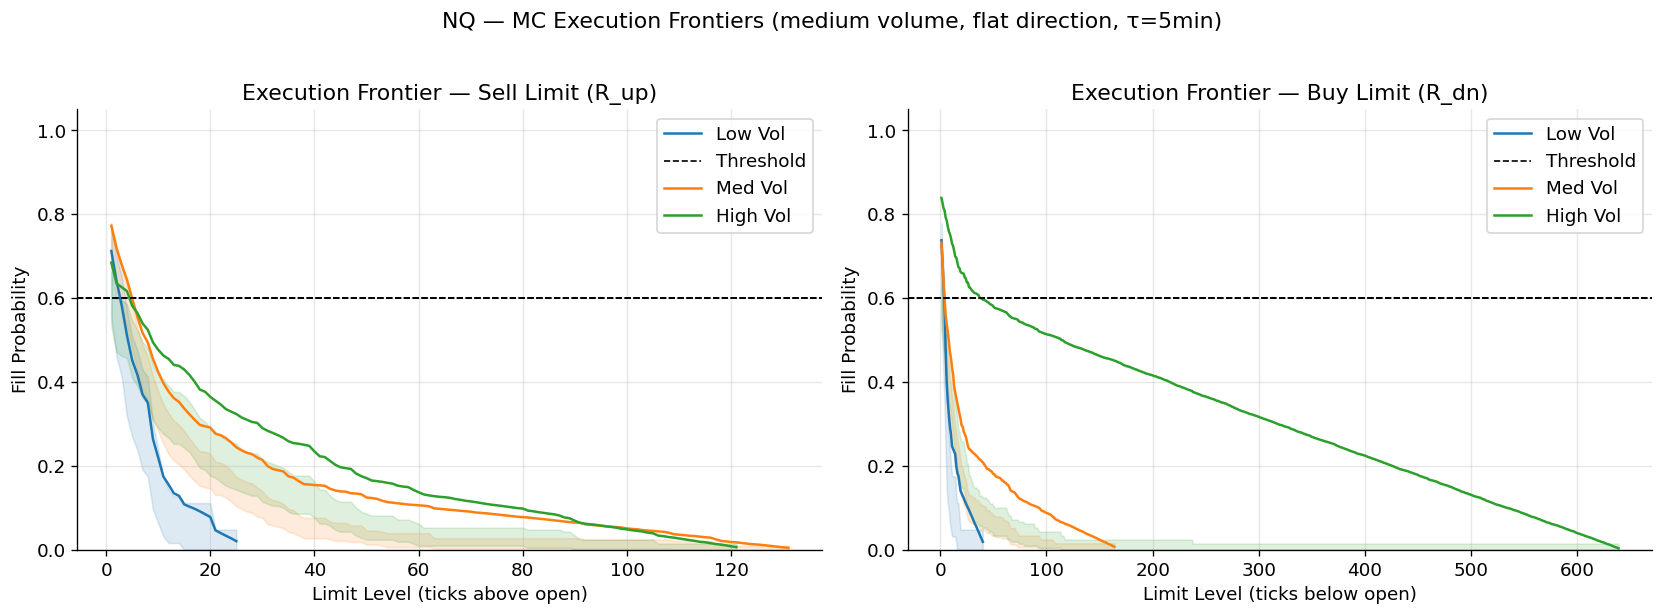


Optimal limit levels (ell*) at fill threshold=0.6:
State (v,s,d)         Sell ell*   Buy ell*  Sell mkt?   Buy mkt?
  (0, 0, 0)                   3          1      False      False
  (0, 0, 1)                   1          3      False      False
  (0, 0, 2)                   2          2      False      False
  (0, 1, 0)                   5          5      False      False
  (0, 1, 1)                   5          4      False      False
  (0, 1, 2)                   5          5      False      False
  (0, 2, 0)                  26         18      False      False
  (0, 2, 1)                  40         83      False      False
  (0, 2, 2)                  18         19      False      False
  (1, 0, 0)                   3          2      False      False
  (1, 0, 1)                   2          3      False      False
  (1, 0, 2)                   4          2      False      False
  (1, 1, 0)                   5          3      False      False
  (1, 1, 1)                   4       

In [40]:
# ─────────────────────────────────────────────
# SECTION 7 — MONTE CARLO EXECUTION SIMULATION
# ─────────────────────────────────────────────

def mc_simulate_execution(
    store: EpdfStore,
    state: Tuple[int, int, int],
    direction: str,             # 'R_up' (sell limit) or 'R_dn' (buy limit)
    fill_prob_threshold: float  = FILL_PROB_THRESHOLD,
    n_paths: int                = N_MC_PATHS,
    bootstrap_reps: int         = BOOTSTRAP_REPS,
    confidence: float           = MC_CONFIDENCE,
    tick_size: float            = TICK_SIZE,
    seed: int                   = RANDOM_SEED,
) -> Dict:
    """
    Monte Carlo simulation of execution outcomes for a given regime state.

    For each candidate limit level ell in {1, ..., L_max}:
      - Sample n_paths future range excursions from the conditional ePDF
      - Compute fill indicator: filled = (sample >= ell)
      - Record expected fill rate and expected improvement

    Also runs bootstrap resampling to quantify ePDF estimation uncertainty.

    Returns
    -------
    dict with keys:
      ell_grid        : candidate limit levels (ticks)
      fill_rate       : simulated fill probability per ell
      exp_improvement : expected improvement (ticks, unfilled=0) per ell
      ci_fill_lo/hi   : bootstrap CI lower/upper on fill rate
      optimal_ell     : argmax improvement s.t. fill_rate >= threshold
      is_market_order : True if no level meets the fill threshold
    """
    rng = np.random.default_rng(seed)

    pmf = store.get_pmf(state, direction)
    L   = len(pmf)

    # ── 1. MC path sampling ──
    samples = rng.choice(L, size=n_paths, p=pmf)   # simulated range excursions

    ell_grid       = np.arange(1, L)
    fill_rates     = np.array([np.mean(samples >= ell) for ell in ell_grid])
    # E[improvement | state, ell]: improvement = ell ticks if filled, 0 otherwise
    exp_improvement = ell_grid * fill_rates   # in ticks

    # ── 2. Bootstrap CI on fill rate ──
    # Resample from historical count array to quantify ePDF estimation uncertainty
    counts = store._counts[state][direction]
    # Expand counts into individual observations
    obs = np.repeat(np.arange(len(counts)), counts.astype(int))

    ci_lo = np.zeros(len(ell_grid))
    ci_hi = np.ones(len(ell_grid))

    if len(obs) >= store.min_samples:
        boot_fill_rates = np.zeros((bootstrap_reps, len(ell_grid)))
        for b in range(bootstrap_reps):
            boot_sample = rng.choice(obs, size=len(obs), replace=True)
            for i, ell in enumerate(ell_grid):
                boot_fill_rates[b, i] = np.mean(boot_sample >= ell)
        alpha = (1 - confidence) / 2
        ci_lo = np.percentile(boot_fill_rates, 100 * alpha,     axis=0)
        ci_hi = np.percentile(boot_fill_rates, 100 * (1-alpha), axis=0)

    # ── 3. Optimal limit level selection ──
    feasible = np.where(fill_rates >= fill_prob_threshold)[0]
    if len(feasible) == 0:
        optimal_ell    = 0
        is_market_order = True
    else:
        # Among feasible levels, pick the one with highest expected improvement
        best_idx       = feasible[np.argmax(exp_improvement[feasible])]
        optimal_ell    = int(ell_grid[best_idx])
        is_market_order = False

    return {
        'ell_grid':        ell_grid,
        'fill_rate':       fill_rates,
        'exp_improvement': exp_improvement,
        'ci_fill_lo':      ci_lo,
        'ci_fill_hi':      ci_hi,
        'optimal_ell':     optimal_ell,
        'is_market_order': is_market_order,
    }


def build_mc_frontier_cache(
    store: EpdfStore,
    m_states: int = M_STATES,
    n_states: int = N_STATES,
    k_states: int = K_STATES,
    fill_prob_threshold: float = FILL_PROB_THRESHOLD,
) -> Dict[Tuple, Dict]:
    """
    Pre-compute MC simulation results for all (state, direction) combinations.
    Cached so the backtest does not re-run MC paths per bar.
    """
    cache = {}
    for vs, ss, ds in product(range(m_states), range(n_states), range(k_states)):
        state = (vs, ss, ds)
        cache[(state, 'R_up')] = mc_simulate_execution(
            store, state, 'R_up', fill_prob_threshold=fill_prob_threshold)
        cache[(state, 'R_dn')] = mc_simulate_execution(
            store, state, 'R_dn', fill_prob_threshold=fill_prob_threshold)
    return cache


# ── Run ──
print("Running Monte Carlo simulations across all states...")
mc_cache = build_mc_frontier_cache(epdf_store)
print(f"  Cached {len(mc_cache)} (state, direction) combinations")

# ── Execution Frontier Plot ──
# Show frontier for 3 volatility states at medium volume (state 1) and flat direction
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
state_labels = {0: 'Low Vol', 1: 'Med Vol', 2: 'High Vol'}
for ss, color in zip(range(N_STATES), PALETTE[:3]):
    state = (1, ss, 1)   # medium volume, varying volatility, flat direction
    for ax_idx, direction in enumerate(['R_up', 'R_dn']):
        res = mc_cache[(state, direction)]
        ax  = axes[ax_idx]
        ax.plot(res['ell_grid'], res['fill_rate'],
                color=color, label=state_labels[ss])
        ax.fill_between(res['ell_grid'], res['ci_fill_lo'], res['ci_fill_hi'],
                        color=color, alpha=0.15)
        ax.axhline(FILL_PROB_THRESHOLD, color='k', linestyle='--',
                   linewidth=1, label='Threshold' if ss==0 else '')

axes[0].set(title='Execution Frontier — Sell Limit (R_up)',
            xlabel='Limit Level (ticks above open)', ylabel='Fill Probability')
axes[1].set(title='Execution Frontier — Buy Limit (R_dn)',
            xlabel='Limit Level (ticks below open)', ylabel='Fill Probability')
for ax in axes:
    ax.legend()
    ax.set_ylim(0, 1.05)
plt.suptitle(f'{ASSET} — MC Execution Frontiers (medium volume, flat direction, τ={TAU}min)',
             y=1.02)
plt.tight_layout()
plt.show()

# Report optimal ell per state
print(f"\nOptimal limit levels (ell*) at fill threshold={FILL_PROB_THRESHOLD}:")
print(f"{'State (v,s,d)':<20} {'Sell ell*':>10} {'Buy ell*':>10} {'Sell mkt?':>10} {'Buy mkt?':>10}")
for vs, ss, ds in product(range(M_STATES), range(N_STATES), range(K_STATES)):
    state = (vs, ss, ds)
    r_up = mc_cache[(state, 'R_up')]
    r_dn = mc_cache[(state, 'R_dn')]
    print(f"  {str(state):<18} {r_up['optimal_ell']:>10} {r_dn['optimal_ell']:>10} "
          f"{str(r_up['is_market_order']):>10} {str(r_dn['is_market_order']):>10}")

---
## Section 8 — AI Agent Signal Integration

**`AIAgent_<Asset>.csv` format:** Each row is a 5-minute bar with columns  
`[excel_date, hour, minute, price, position_size]`

The `position_size` encodes a **dynamic position in units (contracts)**:
- `0` → flat
- `+N` → long N units
- `−N` → short N units

Non-zero transitions within the same sign represent scaling in/out. Sign changes are position reversals.

**Order extraction:** At each bar, `order = position_t − position_{t−1}`.
- `order > 0` → **Buy** (going longer / covering short)
- `order < 0` → **Sell** (going shorter / reducing long)
- `order = 0` → **Flat** (no execution needed)

The signal is aligned to OHLC bars by matching datetime. Bars with no matching AIAgent row default to Flat.  
When `USE_AI_AGENT_SIGNAL = False`, the synthetic momentum signal is used instead (for comparison).


Signal source: AI Agent
Signal distribution:
   Sell (-1): 989 bars (3.5%)
   Flat (+0): 26,297 bars (92.9%)
    Buy (+1): 1,035 bars (3.7%)

AIAgent bars matched to OHLC: 2,024 active signal bars
Order size stats (non-zero orders):
  Mean=3.55, Median=3, Max=17 units


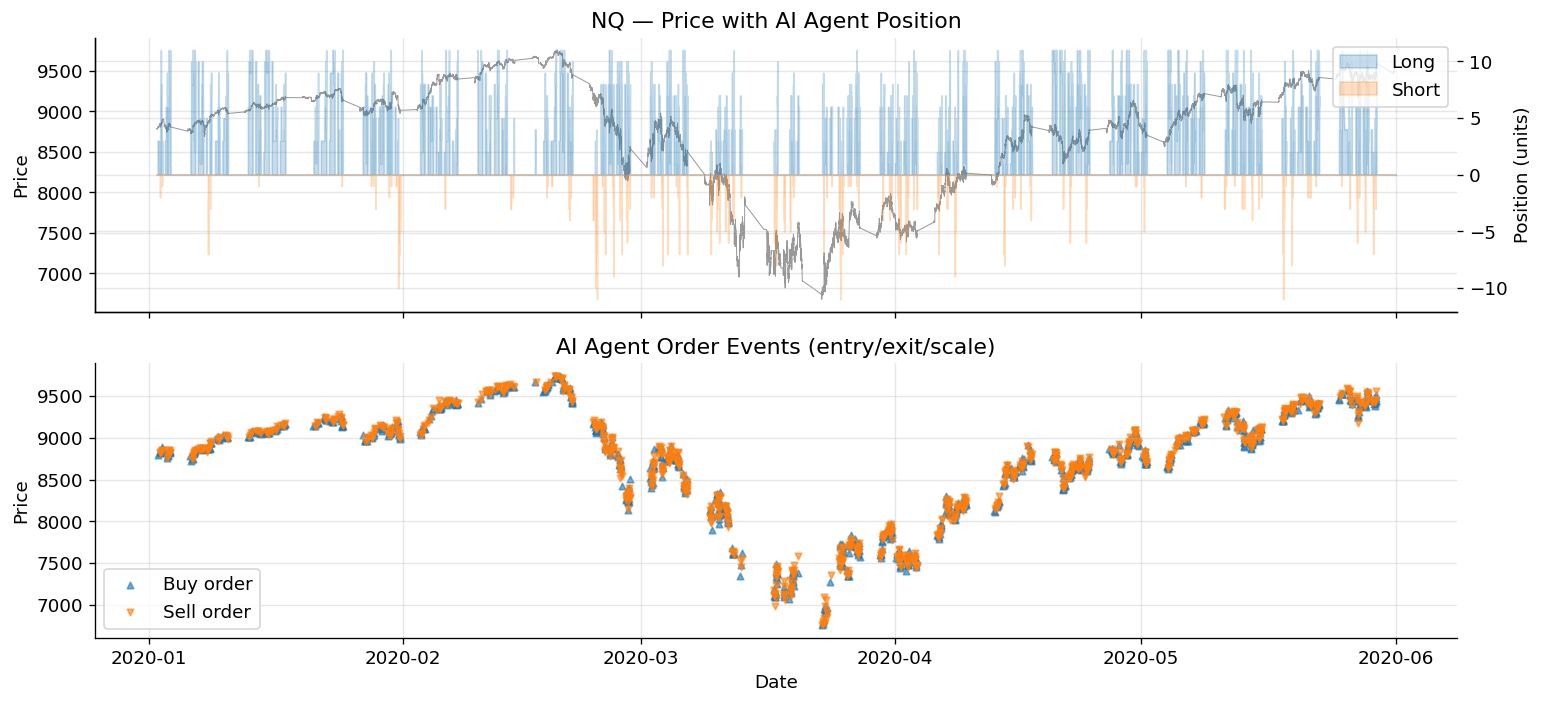

In [41]:
# ─────────────────────────────────────────────
# SECTION 8 — AI AGENT SIGNAL INTEGRATION
# ─────────────────────────────────────────────

def load_ai_agent_signal(asset: str, data_dir: str = DATA_DIR) -> pd.DataFrame:
    """
    Parse the AIAgent CSV for the given asset.

    Returns
    -------
    DataFrame indexed by datetime with columns:
      ai_price    : mid-price recorded by the AI agent at this bar
      position    : AI agent position size (signed units)
      order       : position change vs previous bar (signed units)
      signal      : +1 (Buy), -1 (Sell), 0 (Flat) — derived from order direction
      order_size  : absolute number of units in the order
    """
    meta   = ASSET_REGISTRY[asset]
    fpath  = Path(data_dir) / meta['folder'] / meta['ai_agent']

    rows = []
    with open(fpath) as f:
        for line in f:
            parts = line.strip().split(',')
            if len(parts) < 5:
                continue
            try:
                dt       = _excel_to_date(int(parts[0])).replace(
                               hour=int(parts[1]), minute=int(parts[2]))
                price    = float(parts[3])
                position = int(parts[4])
            except (ValueError, IndexError):
                continue
            rows.append({'datetime': dt, 'ai_price': price, 'position': position})

    ai_df = pd.DataFrame(rows).set_index('datetime').sort_index()

    # Compute order = change in position between consecutive bars
    ai_df['order']      = ai_df['position'].diff().fillna(0).astype(int)
    ai_df['signal']     = np.sign(ai_df['order']).astype(int)   # +1 Buy, -1 Sell, 0 Flat
    ai_df['order_size'] = ai_df['order'].abs()

    return ai_df


def generate_signals(df: pd.DataFrame,
                     asset: str            = ASSET,
                     use_ai_agent: bool    = USE_AI_AGENT_SIGNAL,
                     signal_type: str      = SIGNAL_TYPE,
                     lookback: int         = SIGNAL_LOOKBACK,
                     threshold: float      = SIGNAL_THRESHOLD,
                     tick_size: float      = TICK_SIZE) -> pd.DataFrame:
    """
    Add 'signal' column (+1 Buy, -1 Sell, 0 Flat) and 'order_size' column.

    When use_ai_agent=True: aligns the AIAgent signal to OHLC bars by datetime.
    When use_ai_agent=False: uses synthetic momentum/mean-reversion signal.
    """
    df = df.copy()

    if use_ai_agent:
        ai_df = load_ai_agent_signal(asset, DATA_DIR)

        # Left-join: match AIAgent 5-min bars to OHLC bars by datetime
        # OHLC bar datetime = start of the tau-minute window
        df = df.join(ai_df[['position', 'order', 'signal', 'order_size']],
                     how='left')
        df['signal']     = df['signal'].fillna(0).astype(int)
        df['order_size'] = df['order_size'].fillna(0).astype(int)
        df['position']   = df['position'].fillna(0).astype(int)

    else:
        # Synthetic signal fallback
        threshold_price = threshold * tick_size
        if signal_type == 'momentum':
            ewma_dx    = df['delta_x'].ewm(halflife=lookback, adjust=False).mean()
            signal_raw = ewma_dx.shift(1)
        elif signal_type == 'mean_reversion':
            rolling_mean = df['close'].rolling(lookback).mean()
            signal_raw   = -(df['close'] - rolling_mean).shift(1)
        else:
            raise ValueError(f"Unknown signal_type '{signal_type}'")

        df['signal']     = np.where(signal_raw >  threshold_price,  1,
                           np.where(signal_raw < -threshold_price, -1, 0)).astype(int)
        df['order_size'] = 1   # synthetic: always 1 unit
        df['position']   = 0

    return df


# ── Run ──
ohlc_df = generate_signals(ohlc_df)

mode_label = 'AI Agent' if USE_AI_AGENT_SIGNAL else 'Synthetic Momentum'
signal_counts = ohlc_df['signal'].value_counts().sort_index()
total = len(ohlc_df)
print(f"Signal source: {mode_label}")
print("Signal distribution:")
for s, cnt in signal_counts.items():
    label = {-1: 'Sell', 0: 'Flat', 1: 'Buy'}.get(s, str(s))
    print(f"  {label:>5} ({s:+d}): {cnt:,} bars ({100*cnt/total:.1f}%)")

if USE_AI_AGENT_SIGNAL:
    matched = ohlc_df['signal'].ne(0).sum()
    print(f"\nAIAgent bars matched to OHLC: {matched:,} active signal bars")
    print(f"Order size stats (non-zero orders):")
    nonzero = ohlc_df.loc[ohlc_df['signal'] != 0, 'order_size']
    print(f"  Mean={nonzero.mean():.2f}, Median={nonzero.median():.0f}, "
          f"Max={nonzero.max():.0f} units")

    # Position time-series plot
    fig, axes = plt.subplots(2, 1, figsize=(13, 6), sharex=True)
    pos_series = ohlc_df['position'].replace(0, np.nan)
    axes[0].plot(ohlc_df.index, ohlc_df['close'], color='gray', linewidth=0.6, alpha=0.8)
    axes[0].set(ylabel='Price', title=f'{ASSET} — Price with AI Agent Position')
    ax2 = axes[0].twinx()
    ax2.fill_between(ohlc_df.index,
                     ohlc_df['position'].clip(lower=0), 0,
                     alpha=0.25, color=PALETTE[0], label='Long')
    ax2.fill_between(ohlc_df.index,
                     ohlc_df['position'].clip(upper=0), 0,
                     alpha=0.25, color=PALETTE[1], label='Short')
    ax2.set(ylabel='Position (units)')
    ax2.legend(loc='upper right')

    # Buy/Sell entry markers
    buys  = ohlc_df[ohlc_df['signal'] ==  1]
    sells = ohlc_df[ohlc_df['signal'] == -1]
    axes[1].scatter(buys.index,  buys['close'],  marker='^', s=15,
                    color=PALETTE[0], alpha=0.6, label='Buy order')
    axes[1].scatter(sells.index, sells['close'], marker='v', s=15,
                    color=PALETTE[1], alpha=0.6, label='Sell order')
    axes[1].set(ylabel='Price', xlabel='Date',
                title='AI Agent Order Events (entry/exit/scale)')
    axes[1].legend()
    plt.tight_layout()
    plt.show()


---
## Section 9 — Historical Backtest

We evaluate the execution strategy on the **out-of-sample test period** (bars from `test_start_idx` onward). At each bar with a non-Flat signal:

1. Look up the pre-computed MC optimal limit level `ℓ*` for the current regime state
2. Place a limit order at `open ± ℓ* × tick`
3. Detect fill using the same bar's OHLC (conservative: no intra-bar path information)
4. Record fill outcome vs. market order benchmark

**Fill price assumption:** `fill_price = limit_price`. A real order might receive price improvement if the market trades through the limit, but OHLC data does not carry queue-position information — this is a documented model limitation.

In [42]:
# ─────────────────────────────────────────────
# SECTION 9 — HISTORICAL BACKTEST
# ─────────────────────────────────────────────

def run_backtest(df: pd.DataFrame,
                 mc_cache: Dict,
                 test_start_idx: int,
                 tick_size: float        = TICK_SIZE,
                 fill_prob_threshold: float = FILL_PROB_THRESHOLD) -> pd.DataFrame:
    """
    Out-of-sample execution backtest.

    Processes only bars from test_start_idx onward with signal != 0.
    Uses pre-cached MC results to determine optimal limit level per state.

    Returns
    -------
    trades_df : one row per trade with execution quality metrics
    """
    records = []

    for j in range(test_start_idx, len(df)):
        row = df.iloc[j]

        # Skip Flat signals and pre-burn-in bars
        if row['signal'] == 0:
            continue
        vs, ss, ds = int(row['vol_state']), int(row['sig_state']), int(row['dir_state'])
        if vs < 0 or ss < 0 or ds < 0:
            continue

        state     = (vs, ss, ds)
        signal    = int(row['signal'])    # +1 Buy, -1 Sell
        open_px   = row['open']
        high_px   = row['high']
        low_px    = row['low']

        # Direction determines which ePDF to use
        direction = 'R_up' if signal == -1 else 'R_dn'   # sell→R_up, buy→R_dn

        # Look up MC-optimal limit level from pre-computed cache
        mc_result = mc_cache.get((state, direction))
        if mc_result is None:
            optimal_ell    = 0
            is_market_order = True
        else:
            optimal_ell     = mc_result['optimal_ell']
            is_market_order = mc_result['is_market_order']

        # ── Place order ──
        if is_market_order or optimal_ell == 0:
            # Fallback: market order at open
            limit_price     = open_px
            fill_price      = open_px
            filled          = True
            is_market_order = True
            improvement     = 0.0
        else:
            if signal == -1:   # Sell: place limit above open
                limit_price = open_px + optimal_ell * tick_size
                filled      = high_px >= limit_price
            else:              # Buy: place limit below open
                limit_price = open_px - optimal_ell * tick_size
                filled      = low_px  <= limit_price

            if filled:
                fill_price  = limit_price
                # Improvement = how much better than open (positive = good)
                if signal == -1:
                    improvement = (fill_price - open_px) / tick_size   # sold higher
                else:
                    improvement = (open_px - fill_price) / tick_size   # bought lower
            else:
                fill_price  = np.nan
                improvement = 0.0   # unfilled: treat as market order (0 improvement)

        records.append({
            'bar_time':            df.index[j],
            'signal':              signal,
            'vol_state':           vs,
            'sig_state':           ss,
            'dir_state':           ds,
            'state':               state,
            'direction':           direction,
            'open_price':          open_px,
            'limit_level_ticks':   optimal_ell,
            'limit_price':         limit_price,
            'filled':              filled,
            'fill_price':          fill_price,
            'improvement_ticks':   improvement,
            'is_market_fallback':  is_market_order,
        })

    if not records:
        return pd.DataFrame(columns=[
            'signal', 'vol_state', 'sig_state', 'dir_state', 'state',
            'direction', 'open_price', 'limit_level_ticks', 'limit_price',
            'filled', 'fill_price', 'improvement_ticks', 'is_market_fallback',
        ])
    return pd.DataFrame(records).set_index('bar_time')


# ── Run ──
print("Running out-of-sample backtest...")
trades_df = run_backtest(ohlc_df, mc_cache, test_start_idx)

n_trades   = len(trades_df)
n_limit    = (~trades_df['is_market_fallback']).sum()
n_filled   = trades_df['filled'].sum()
fill_rate  = trades_df.loc[~trades_df['is_market_fallback'], 'filled'].mean()
mean_impr  = trades_df.loc[trades_df['filled'] & ~trades_df['is_market_fallback'],
                            'improvement_ticks'].mean()

print(f"  Total trades:      {n_trades:,}")
print(f"  Limit orders:      {n_limit:,} ({100*n_limit/n_trades:.1f}%)")
print(f"  Market fallbacks:  {n_trades - n_limit:,}")
print(f"  Fill rate (limit): {fill_rate:.2%}")
print(f"  Mean improvement (filled limit): {mean_impr:.2f} ticks")

Running out-of-sample backtest...
  Total trades:      919
  Limit orders:      919 (100.0%)
  Market fallbacks:  0
  Fill rate (limit): 61.59%
  Mean improvement (filled limit): 5.60 ticks


---
## Section 10 — Evaluation, Sensitivity & Results

We report execution quality across four dimensions:
1. **Summary metrics**: fill rate, mean improvement, calibration
2. **Regime breakdown**: performance by vol/volatility/direction state
3. **ePDF visualization**: replicating Figure 2 from the project spec
4. **Sensitivity analysis**: robustness to τ, half-life, states, threshold
5. **Cross-asset comparison**: NQ vs GC

In [43]:
# ─────────────────────────────────────────────
# SECTION 10a — SUMMARY METRICS
# ─────────────────────────────────────────────

def compute_summary_metrics(trades: pd.DataFrame, asset_label: str = ASSET) -> pd.DataFrame:
    """Compute key execution quality metrics from trades DataFrame."""
    limit_trades = trades[~trades['is_market_fallback']]
    filled_limit = limit_trades[limit_trades['filled']]

    all_impr   = trades['improvement_ticks']   # unfilled=0, market=0

    summary = {
        'Asset':                      asset_label,
        'Total trades':               len(trades),
        'Limit orders placed':        len(limit_trades),
        'Market fallbacks':           len(trades) - len(limit_trades),
        'Fill rate (limit)':          f"{limit_trades['filled'].mean():.2%}",
        'Mean improvement | filled':  f"{filled_limit['improvement_ticks'].mean():.2f} ticks",
        'Effective improvement':      f"{all_impr[all_impr > 0].mean():.2f} ticks",
        'Buy fill rate':              f"{limit_trades[limit_trades['signal']==1]['filled'].mean():.2%}",
        'Sell fill rate':             f"{limit_trades[limit_trades['signal']==-1]['filled'].mean():.2%}",
    }
    return pd.Series(summary)


summary = compute_summary_metrics(trades_df)
print("=" * 50)
print(f"  EXECUTION QUALITY SUMMARY — {ASSET}")
print("=" * 50)
for k, v in summary.items():
    print(f"  {k:<35} {v}")

# Regime breakdown
print("\nPerformance by regime state:")
regime_stats = (trades_df[~trades_df['is_market_fallback']]
                .groupby(['vol_state', 'sig_state'])
                .agg(
                    n_trades     = ('filled', 'count'),
                    fill_rate    = ('filled', 'mean'),
                    mean_impr    = ('improvement_ticks', 'mean'),
                )
                .round(3))
print(regime_stats.to_string())

  EXECUTION QUALITY SUMMARY — NQ
  Asset                               NQ
  Total trades                        919
  Limit orders placed                 919
  Market fallbacks                    0
  Fill rate (limit)                   61.59%
  Mean improvement | filled           5.60 ticks
  Effective improvement               5.60 ticks
  Buy fill rate                       61.57%
  Sell fill rate                      61.61%

Performance by regime state:
                     n_trades  fill_rate  mean_impr
vol_state sig_state                                
0         0                40      0.575      1.025
          1               236      0.581      2.877
          2                11      0.455      9.727
1         0                 2      0.500      1.500
          1               211      0.649      2.588
          2                51      0.569      5.039
2         1               167      0.659      3.198
          2               201      0.617      5.000


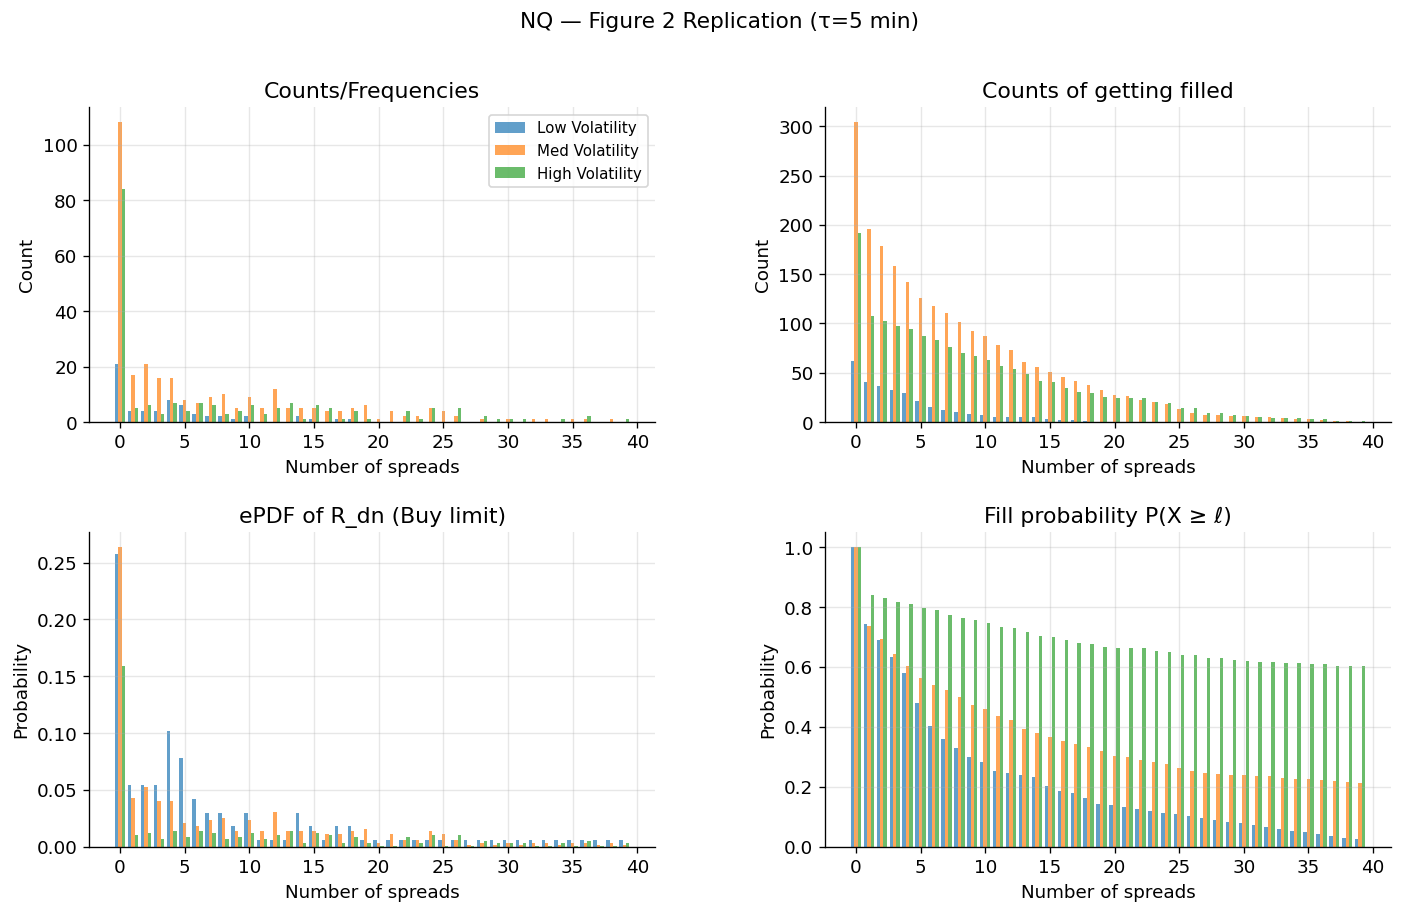

In [44]:
# ─────────────────────────────────────────────
# SECTION 10b — ePDF VISUALIZATION (Figure 2 replication)
# ─────────────────────────────────────────────

def plot_epdf_figure2(store: EpdfStore,
                      states_to_show: List[Tuple],
                      direction: str = 'R_dn',
                      labels: Optional[List[str]] = None,
                      title_prefix: str = '') -> None:
    """
    Replicate Figure 2 from the project spec:
    - top-left:    raw count frequencies as function of tick count
    - bottom-left: normalized PMF
    - top-right:   counts of getting filled at each tick level
    - bottom-right: fill probability P(R >= ell)
    """
    if labels is None:
        labels = [str(s) for s in states_to_show]

    colors = PALETTE[:len(states_to_show)]
    max_ell = 0
    for state in states_to_show:
        pmf = store.get_pmf(state, direction)
        max_ell = max(max_ell, len(pmf))
    max_ell = min(max_ell, 40)  # cap display at 40 ticks

    fig = plt.figure(figsize=(14, 8))
    gs  = gridspec.GridSpec(2, 2, hspace=0.35, wspace=0.3)
    ax_tl = fig.add_subplot(gs[0, 0])  # counts
    ax_bl = fig.add_subplot(gs[1, 0])  # PMF
    ax_tr = fig.add_subplot(gs[0, 1])  # fill counts
    ax_br = fig.add_subplot(gs[1, 1])  # fill probability

    x = np.arange(max_ell)
    bar_w = 0.8 / len(states_to_show)

    for i, (state, label, color) in enumerate(zip(states_to_show, labels, colors)):
        counts = store._counts[state][direction]
        n      = min(len(counts), max_ell)
        c_vals = np.zeros(max_ell)
        c_vals[:n] = counts[:n]

        pmf  = store.get_pmf(state, direction)[:max_ell]
        pmf  = np.pad(pmf, (0, max_ell - len(pmf)))
        surv = store.get_survival(state, direction)[:max_ell]
        surv = np.pad(surv, (0, max_ell - len(surv)))

        # Fill counts: c_vals[ell] * P(X >= ell) but as raw counts
        fill_counts = np.array([c_vals[ell:].sum() for ell in range(max_ell)])

        offset = (i - len(states_to_show)/2 + 0.5) * bar_w
        ax_tl.bar(x + offset, c_vals,       width=bar_w, color=color, alpha=0.7, label=label)
        ax_bl.bar(x + offset, pmf,           width=bar_w, color=color, alpha=0.7)
        ax_tr.bar(x + offset, fill_counts,   width=bar_w, color=color, alpha=0.7)
        ax_br.bar(x + offset, surv,          width=bar_w, color=color, alpha=0.7)

    dir_label = 'R_up (Sell limit)' if direction == 'R_up' else 'R_dn (Buy limit)'
    ax_tl.set(title='Counts/Frequencies', xlabel='Number of spreads', ylabel='Count')
    ax_bl.set(title=f'ePDF of {dir_label}', xlabel='Number of spreads', ylabel='Probability')
    ax_tr.set(title='Counts of getting filled', xlabel='Number of spreads', ylabel='Count')
    ax_br.set(title='Fill probability P(X ≥ ℓ)', xlabel='Number of spreads', ylabel='Probability')
    ax_tl.legend(fontsize=9)
    fig.suptitle(f'{title_prefix}{ASSET} — Figure 2 Replication (τ={TAU} min)', fontsize=13)
    plt.show()


# Show ePDFs for the 3 volatility states (medium volume, flat direction)
states_fig2  = [(1, 0, 1), (1, 1, 1), (1, 2, 1)]
labels_fig2  = ['Low Volatility', 'Med Volatility', 'High Volatility']
plot_epdf_figure2(epdf_store, states_fig2, direction='R_dn',
                  labels=labels_fig2, title_prefix='')

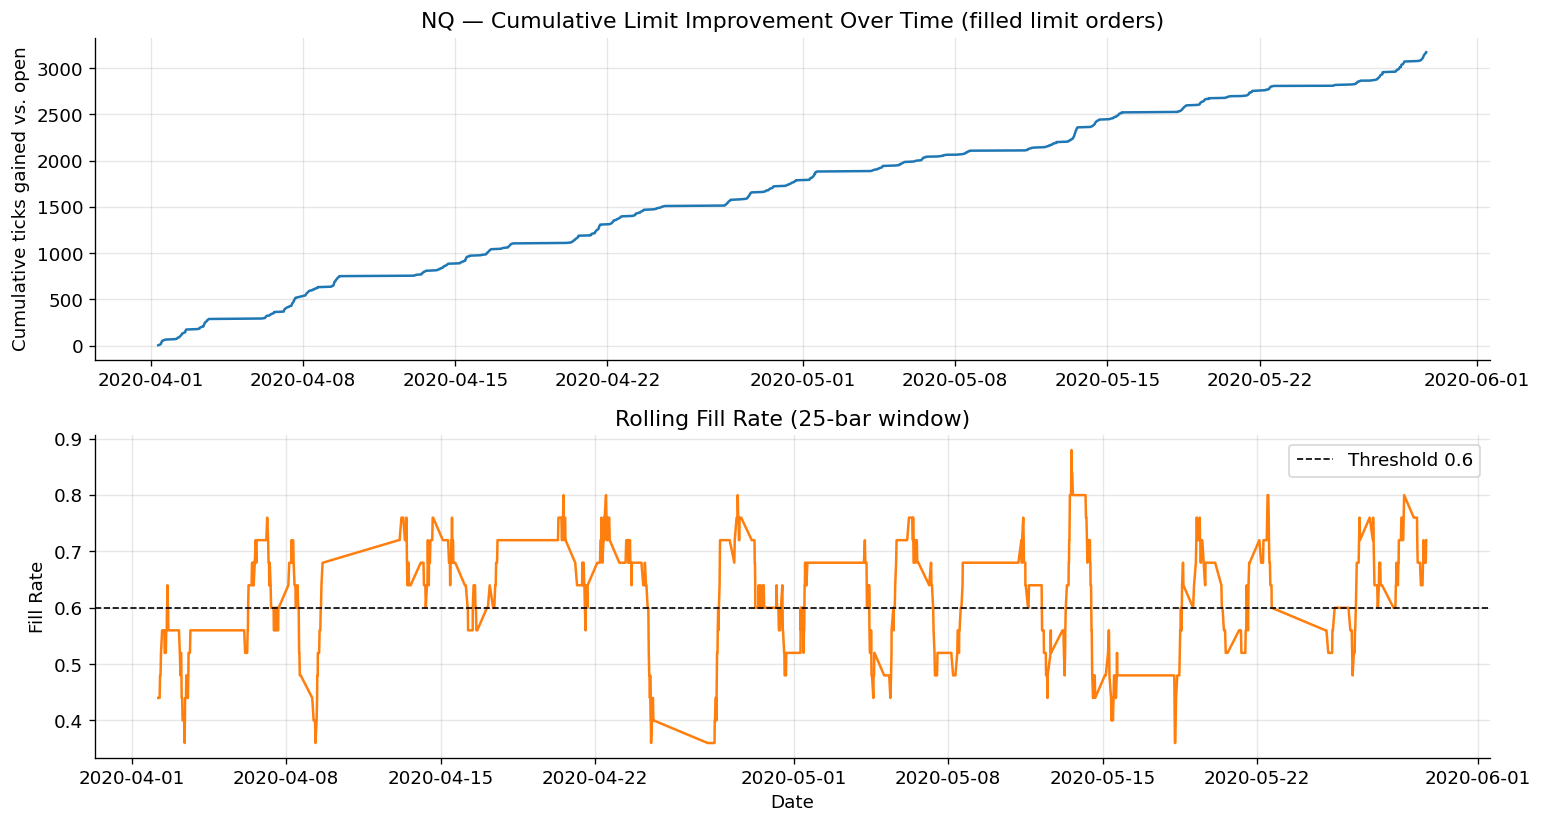

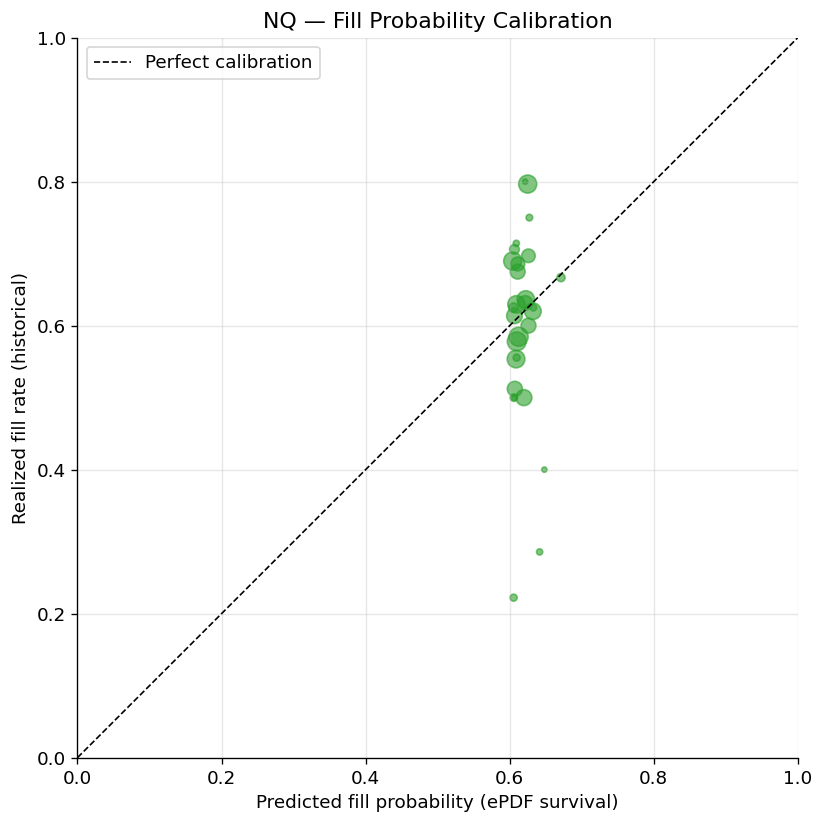

In [45]:
# ─────────────────────────────────────────────
# SECTION 10c — CALIBRATION & TIME-SERIES PLOTS
# ─────────────────────────────────────────────

# 1. Cumulative improvement over time
filled_limit_trades = trades_df[
    ~trades_df['is_market_fallback'] & trades_df['filled']
].copy()

fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=False)

# Cumulative improvement
cum_impr = filled_limit_trades['improvement_ticks'].cumsum()
axes[0].plot(cum_impr.index, cum_impr.values, color=PALETTE[0])
axes[0].set(title=f'{ASSET} — Cumulative Limit Improvement Over Time (filled limit orders)',
            ylabel='Cumulative ticks gained vs. open')

# Rolling fill rate (25-bar window)
limit_df = trades_df[~trades_df['is_market_fallback']].copy()
rolling_fill = limit_df['filled'].rolling(25).mean()
axes[1].plot(rolling_fill.index, rolling_fill.values, color=PALETTE[1])
axes[1].axhline(FILL_PROB_THRESHOLD, color='k', linestyle='--', linewidth=1,
                label=f'Threshold {FILL_PROB_THRESHOLD}')
axes[1].set(title='Rolling Fill Rate (25-bar window)',
            ylabel='Fill Rate', xlabel='Date')
axes[1].legend()
plt.tight_layout()
plt.show()

# 2. Calibration scatter: predicted fill probability vs. realized fill rate
# Group by (state, limit_level_ticks) and compare predicted vs. actual
calib_records = []
for (state, direction), group in limit_df.groupby(['state', 'direction']):
    for ell, sub in group.groupby('limit_level_ticks'):
        if len(sub) < 5:
            continue
        predicted = epdf_store.fill_prob(state, direction, int(ell))
        realized  = sub['filled'].mean()
        calib_records.append({'predicted': predicted, 'realized': realized,
                              'n': len(sub)})

calib_df = pd.DataFrame(calib_records)
if not calib_df.empty:
    fig, ax = plt.subplots(figsize=(7, 7))
    sc = ax.scatter(calib_df['predicted'], calib_df['realized'],
                    s=calib_df['n'] * 2, alpha=0.6, color=PALETTE[2])
    ax.plot([0, 1], [0, 1], 'k--', linewidth=1, label='Perfect calibration')
    ax.set(title=f'{ASSET} — Fill Probability Calibration',
           xlabel='Predicted fill probability (ePDF survival)',
           ylabel='Realized fill rate (historical)',
           xlim=(0, 1), ylim=(0, 1))
    ax.legend()
    plt.tight_layout()
    plt.show()
else:
    print("  Not enough (state, ell) groups with >=5 trades for calibration plot.")

Sensitivity Analysis — NQ: Fill Rate by (τ, Threshold)
threshold    0.5    0.6    0.7    0.8
tau                                  
5          0.539  0.616  0.681  0.833
10         0.539  0.617  0.711  0.768
15         0.495  0.598  0.704  0.791
30         0.340  0.524  0.640  0.745

Sensitivity Analysis — NQ: Mean Improvement (ticks) by (τ, Threshold)
threshold     0.5     0.6     0.7     0.8
tau                                      
5          10.228   5.604   1.566   1.000
10         22.342  14.299   8.181   3.359
15         33.050  22.852  13.629   5.783
30         68.141  47.207  31.109  17.555


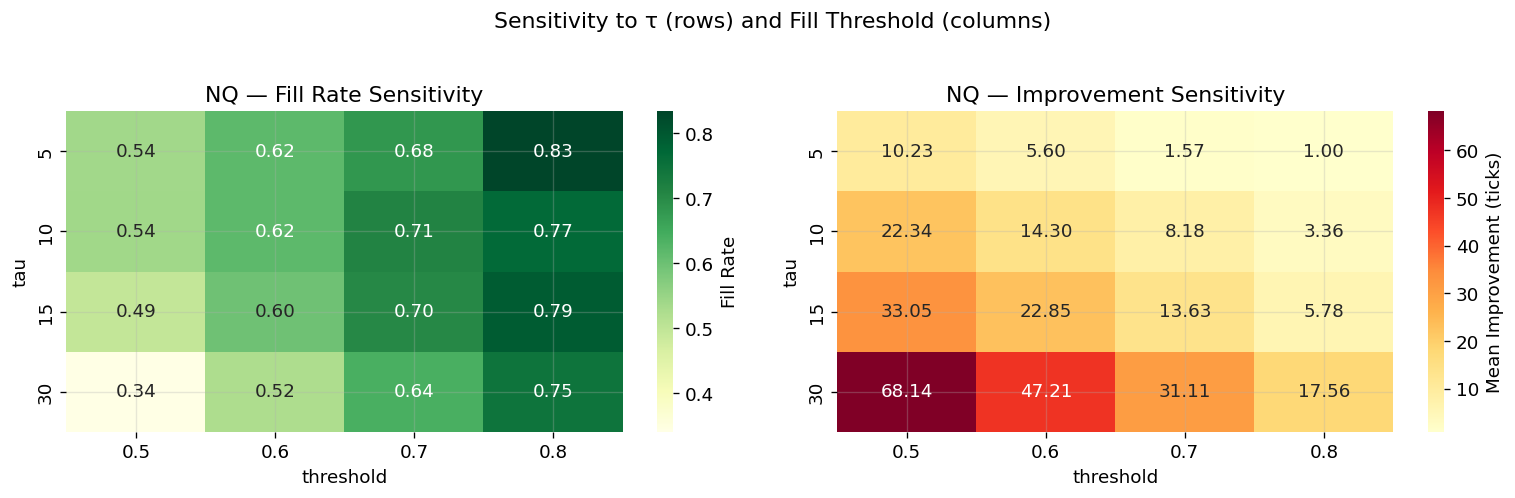

In [47]:
# ─────────────────────────────────────────────
# SECTION 10d — SENSITIVITY ANALYSIS
# ─────────────────────────────────────────────

def run_pipeline(asset: str,
                 tau: int,
                 half_life: int,
                 n_states: int,
                 fill_threshold: float,
                 smoothing: float = 0.5) -> Dict:
    """
    Run the full pipeline with given hyperparameters and return summary metrics.
    Used for sensitivity analysis and cross-asset comparison.
    """
    meta      = ASSET_REGISTRY[asset]
    tick      = meta['tick_size']

    _raw  = load_data(asset, DATA_DIR, MIN_BARS_PER_DAY)
    _ohlc = build_ohlc(_raw, tau)
    _ohlc = compute_ranges(_ohlc, tick)
    _ohlc = compute_ewma_states(_ohlc,
                                half_life=half_life,
                                m_states=n_states,
                                n_states=n_states,
                                k_states=n_states)
    _ohlc = generate_signals(_ohlc, asset=asset, tick_size=tick)

    _store, _test_idx = build_epdf(_ohlc,
                                   smoothing_alpha=smoothing,
                                   min_samples=MIN_EPDF_SAMPLES)
    _cache = build_mc_frontier_cache(_store,
                                     m_states=n_states,
                                     n_states=n_states,
                                     k_states=n_states,
                                     fill_prob_threshold=fill_threshold)
    _trades = run_backtest(_ohlc, _cache, _test_idx,
                           tick_size=tick,
                           fill_prob_threshold=fill_threshold)

    if _trades.empty:
        return {'fill_rate': np.nan, 'mean_improvement': np.nan, 'n_trades': 0}

    lim = _trades[~_trades['is_market_fallback']]
    fl  = lim[lim['filled']]
    return {
        'fill_rate':        lim['filled'].mean() if len(lim) > 0 else np.nan,
        'mean_improvement': fl['improvement_ticks'].mean() if len(fl) > 0 else np.nan,
        'n_trades':         len(lim),
    }


# ── Sensitivity grid (τ × threshold — keep others at default) ──
# Suppress output from sub-runs
import io, sys

sens_results = []
for tau_val in [5, 10, 15, 30]:
    for thresh in [0.50, 0.60, 0.70, 0.80]:
        old_stdout = sys.stdout
        sys.stdout = io.StringIO()
        try:
            res = run_pipeline(ASSET, tau_val, HALF_LIFE, M_STATES, thresh)
        finally:
            sys.stdout = old_stdout
        sens_results.append({
            'tau':              tau_val,
            'threshold':        thresh,
            'fill_rate':        res['fill_rate'],
            'mean_improvement': res['mean_improvement'],
            'n_trades':         res['n_trades'],
        })

sens_df = pd.DataFrame(sens_results)

print(f"Sensitivity Analysis — {ASSET}: Fill Rate by (τ, Threshold)")
pivot_fill = sens_df.pivot(index='tau', columns='threshold', values='fill_rate')
print(pivot_fill.round(3).to_string())

print(f"\nSensitivity Analysis — {ASSET}: Mean Improvement (ticks) by (τ, Threshold)")
pivot_impr = sens_df.pivot(index='tau', columns='threshold', values='mean_improvement')
print(pivot_impr.round(3).to_string())

# Heatmap
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.heatmap(pivot_fill,  annot=True, fmt='.2f', cmap='YlGn',
            ax=axes[0], cbar_kws={'label': 'Fill Rate'})
sns.heatmap(pivot_impr, annot=True, fmt='.2f', cmap='YlOrRd',
            ax=axes[1], cbar_kws={'label': 'Mean Improvement (ticks)'})
axes[0].set(title=f'{ASSET} — Fill Rate Sensitivity')
axes[1].set(title=f'{ASSET} — Improvement Sensitivity')
plt.suptitle('Sensitivity to τ (rows) and Fill Threshold (columns)', y=1.03)
plt.tight_layout()
plt.show()

In [48]:
# ─────────────────────────────────────────────
# SECTION 10e — CROSS-ASSET COMPARISON (NQ vs GC)
# ─────────────────────────────────────────────

print("Running cross-asset comparison (NQ vs GC)...")
cross_asset_results = []
for asset_name in ['NQ', 'GC']:
    tick = ASSET_REGISTRY[asset_name]['tick_size']
    old_stdout = sys.stdout
    sys.stdout = io.StringIO()
    try:
        res = run_pipeline(asset_name, TAU, HALF_LIFE, M_STATES, FILL_PROB_THRESHOLD)
    finally:
        sys.stdout = old_stdout
    cross_asset_results.append({
        'Asset':                    asset_name,
        'Tick Size':                tick,
        'Trades (limit)':           res['n_trades'],
        'Fill Rate':                f"{res['fill_rate']:.2%}" if not np.isnan(res['fill_rate']) else 'N/A',
        'Mean Improvement (ticks)': f"{res['mean_improvement']:.2f}" if not np.isnan(res['mean_improvement']) else 'N/A',
    })

cross_df = pd.DataFrame(cross_asset_results).set_index('Asset')
print("\nCross-Asset Execution Quality Summary:")
print(cross_df.to_string())

Running cross-asset comparison (NQ vs GC)...

Cross-Asset Execution Quality Summary:
       Tick Size  Trades (limit) Fill Rate Mean Improvement (ticks)
Asset                                                              
NQ          0.25             919    61.59%                     5.60
GC          0.10             574    64.63%                     1.87
